In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#INSPECCION DEL DATASET
import os
import zipfile
import pandas as pd
from google.colab import files

zip_path = '/content/archive.zip'

if not os.path.exists(zip_path):
    uploaded = files.upload()
    zip_path = list(uploaded.keys())[0]

extract_dir = '/content/dataset'
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

dict_path = os.path.join(extract_dir, 'data_dictionary.md')
if os.path.exists(dict_path):
    print("================ DATA DICTIONARY ================")
    with open(dict_path, 'r', encoding='utf-8') as f:
        print(f.read())
    print("=================================================\n")

csv_files = ['scenarios.csv', 'results.csv', 'seed_summary.csv', 'summary.csv']

for name in csv_files:
    file_path = os.path.join(extract_dir, name)
    df = pd.read_csv(file_path)
    print(f"=== {name} | Filas: {df.shape[0]}, Columnas: {df.shape[1]} ===")
    print(df.dtypes)

    nulos = df.isnull().sum()
    print("Nulos:", nulos[nulos > 0].to_dict() if nulos.sum() > 0 else "Ninguno (0 nulos)")

    for col in df.columns:
        if df[col].nunique() <= 10:
            print(f"  -> Distribución '{col}': {df[col].value_counts(dropna=False).to_dict()}")

    print(df.head(2), "\n" + "-"*60 + "\n")

Saving archive.zip to archive.zip
================ DATA DICTIONARY ================
# Data dictionary

## `data/scenarios.csv`

- `scenario_id`: deterministic identifier for one synthetic scenario.
- `seed`, `task_index`: random seed and within-condition task number.
- `poisoning_rate`: nominal probability of adding a poisoned candidate (0, 0.10, or 0.25); realised sample proportions can differ.
- `poison_present`: whether the synthetic poisoned candidate was included (0/1).
- `primary_clean_relevance`, `primary_clean_trust`, `primary_clean_corroboration`: features for the expected clean memory.
- `secondary_clean_relevance`, `secondary_clean_trust`, `secondary_clean_corroboration`: features for a lower-relevance clean distractor.
- `poison_relevance`, `poison_trust`, `poison_corroboration`: features for the injected candidate; blank when no poisoned candidate exists.
- `expected_memory_id`: always `clean_primary` in this benchmark.
- `poisoned_memory_id`: label of the injected candida

In [ ]:
#PREPROCESAMIENTO DE DATOS
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from imblearn.over_sampling import SMOTE

# 1. Carga e integración relacional (scenarios + results)
scenarios = pd.read_csv('/content/dataset/scenarios.csv')
results = pd.read_csv('/content/dataset/results.csv')

# Eliminamos columnas redundantes antes del merge para evitar sufijos _x, _y
cols_redundantes = ['seed', 'poisoning_rate', 'poison_present']
df = pd.merge(results, scenarios.drop(columns=cols_redundantes), on='scenario_id', how='inner')

print(f"Dataset consolidado: {df.shape[0]} filas x {df.shape[1]} columnas")

# 2. Selección de atributos (eliminación de IDs, constantes y variables con data leakage)
cols_excluir = [
    'scenario_id', 'seed', 'task_index', 'scenario_note',          # Metadatos / Constantes
    'expected_memory_id', 'poisoned_memory_id', 'abstained',       # Constantes / Redundantes
    'selected_memory_id', 'selected_memory_is_poisoned', 'task_success'  # Post-decisión (Data Leakage)
]

target_col = 'attack_success'
y = df[target_col].copy()
X = df.drop(columns=cols_excluir + [target_col]).copy()

# 3.1 Tratamiento de valores faltantes (Imputación determinista 0.0 para candidatos ausentes)
print("\nValores faltantes antes de imputar:")
print(X.isnull().sum()[X.isnull().sum() > 0])

cols_poison_nulos = ['poison_relevance', 'poison_trust', 'poison_corroboration']
X[cols_poison_nulos] = X[cols_poison_nulos].fillna(0.0)

print("Valores faltantes después de imputar:", X.isnull().sum().sum())

# 3.3 Ingeniería de características (Variables diferenciales de competencia entre memorias)
X['diff_relevance_poison'] = X['poison_relevance'] - X['primary_clean_relevance']
X['diff_trust_poison'] = X['poison_trust'] - X['primary_clean_trust']
X['diff_corrob_poison'] = X['poison_corroboration'] - X['primary_clean_corroboration']
X['diff_relevance_distractor'] = X['primary_clean_relevance'] - X['secondary_clean_relevance']

# 3.2 y 3.3 Codificación One-Hot (policy) y Estandarización Z-score
cat_cols = ['policy']
num_cols = [col for col in X.columns if col not in cat_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ]
)

# Ejemplo de verificación con partición estratificada 80/20 (sin data leakage)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Ajustar preprocesador solo en Train
X_train_scaled = preprocessor.fit_transform(X_train_raw)
X_test_scaled = preprocessor.transform(X_test_raw)

# Recuperar nombres de las 17 columnas transformadas
feature_names = num_cols + list(preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols))
print(f"\nTotal de características tras One-Hot + Feature Engineering: {len(feature_names)}")
print("Lista de features:", feature_names)

# 3.4 Balanceo de datos con SMOTE (aplicado exclusivamente a Train)
print("\nDistribución de clases en Train ANTES de SMOTE:", pd.Series(y_train).value_counts().to_dict())

smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)

print("Distribución de clases en Train DESPUÉS de SMOTE:", pd.Series(y_train_bal).value_counts().to_dict())
print("Distribución de clases en Test (intacta):", pd.Series(y_test).value_counts().to_dict())

Dataset consolidado: 6750 filas x 24 columnas

Valores faltantes antes de imputar:
poison_relevance        5910
poison_trust            5910
poison_corroboration    5910
dtype: int64
Valores faltantes después de imputar: 0

Total de características tras One-Hot + Feature Engineering: 18
Lista de features: ['poisoning_rate', 'poison_present', 'candidates_considered', 'primary_clean_relevance', 'primary_clean_trust', 'primary_clean_corroboration', 'secondary_clean_relevance', 'secondary_clean_trust', 'secondary_clean_corroboration', 'poison_relevance', 'poison_trust', 'poison_corroboration', 'diff_relevance_poison', 'diff_trust_poison', 'diff_corrob_poison', 'diff_relevance_distractor', 'policy_provenance_filter', 'policy_provenance_plus_corroboration']

Distribución de clases en Train ANTES de SMOTE: {0: 5206, 1: 194}
Distribución de clases en Train DESPUÉS de SMOTE: {0: 5206, 1: 5206}
Distribución de clases en Test (intacta): {0: 1302, 1: 48}


=== Verificación Rápida de Clasificadores (Split 80/20) ===

--- Random Forest (Principal) ---
ROC-AUC Score: 1.0000
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000      1302
           1     1.0000    1.0000    1.0000        48

    accuracy                         1.0000      1350
   macro avg     1.0000    1.0000    1.0000      1350
weighted avg     1.0000    1.0000    1.0000      1350


--- SVM - Kernel RBF (Contraste) ---
ROC-AUC Score: 0.9999
              precision    recall  f1-score   support

           0     1.0000    0.9946    0.9973      1302
           1     0.8727    1.0000    0.9320        48

    accuracy                         0.9948      1350
   macro avg     0.9364    0.9973    0.9647      1350
weighted avg     0.9955    0.9948    0.9950      1350


=== Ranking de Importancia de Características (Random Forest) ===
                      Característica  Importancia_Gini
               candidates_considered          0

/tmp/ipykernel_666/3218808171.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


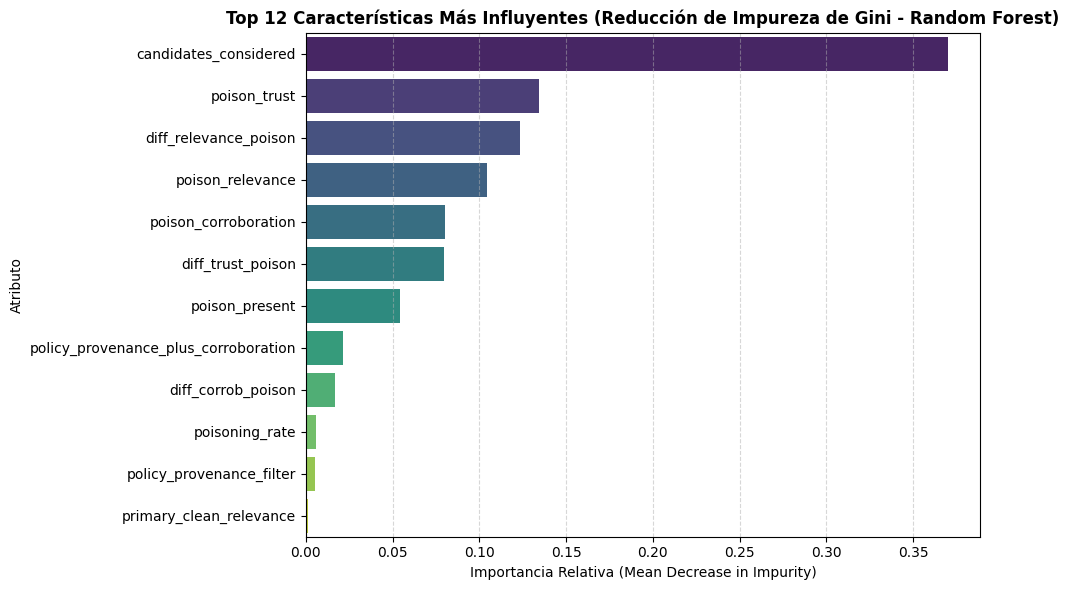

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.metrics import classification_report, roc_auc_score

# Función constructora del Pipeline completo (Preprocesamiento -> SMOTE -> Clasificador)
# Usar ImbPipeline asegura que SMOTE y StandardScaler se ajusten SOLO en cada fold de entrenamiento
def construir_pipeline(modelo='rf', random_state=42):
    if modelo == 'rf':
        clf = RandomForestClassifier(
            n_estimators=100,
            max_features='sqrt',      # m = sqrt(p) = sqrt(17) ≈ 4 variables por nodo (Breiman, 2001)
            criterion='gini',         # Impureza de Gini
            random_state=random_state,
            n_jobs=-1
        )
    elif modelo == 'svm':
        clf = SVC(
            kernel='rbf',
            C=1.0,
            gamma='scale',
            probability=True,
            random_state=random_state
        )
    else:
        raise ValueError("Modelo no soportado. Usa 'rf' o 'svm'.")

    return ImbPipeline(steps=[
        ('preprocessor', preprocessor),
        ('smote', SMOTE(random_state=random_state)),
        ('classifier', clf)
    ])

# Instanciamos ambos modelos para validar su funcionamiento y comparar importancia de variables
pipeline_rf = construir_pipeline(modelo='rf', random_state=42)
pipeline_svm = construir_pipeline(modelo='svm', random_state=42)

# Entrenamiento rápido de verificación sobre la partición 80/20 del Punto 3
pipeline_rf.fit(X_train_raw, y_train)
pipeline_svm.fit(X_train_raw, y_train)

print("=== Verificación Rápida de Clasificadores (Split 80/20) ===")
for nombre, pipe in [('Random Forest (Principal)', pipeline_rf), ('SVM - Kernel RBF (Contraste)', pipeline_svm)]:
    y_pred = pipe.predict(X_test_raw)
    y_prob = pipe.predict_proba(X_test_raw)[:, 1]
    print(f"\n--- {nombre} ---")
    print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")
    print(classification_report(y_test, y_pred, digits=4))

# Extracción de Importancia de Características (Gini Importance) del Random Forest
rf_model = pipeline_rf.named_steps['classifier']
importancias = pd.DataFrame({
    'Característica': feature_names,
    'Importancia_Gini': rf_model.feature_importances_
}).sort_values(by='Importancia_Gini', ascending=False)

print("\n=== Ranking de Importancia de Características (Random Forest) ===")
print(importancias.to_string(index=False))

# Gráfico listo para insertar en la Sección 4 o 5 de tu artículo
plt.figure(figsize=(10, 6))
sns.barplot(
    data=importancias.head(12),
    x='Importancia_Gini',
    y='Característica',
    palette='viridis'
)
plt.title('Top 12 Características Más Influyentes (Reducción de Impureza de Gini - Random Forest)', fontsize=12, fontweight='bold')
plt.xlabel('Importancia Relativa (Mean Decrease in Impurity)', fontsize=10)
plt.ylabel('Atributo', fontsize=10)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

=== 5.1 CONFIABILIDAD DEL MODELO (Split 80/20 - Random Forest) ===
              Métrica  Valor
 Exactitud (Accuracy) 1.0000
Precisión (Precision) 1.0000
Sensibilidad (Recall) 1.0000
             F1-Score 1.0000
              ROC-AUC 1.0000
 Coef. Matthews (MCC) 1.0000

=== 5.2 DESGLOSE DE LA MATRIZ DE CONFUSIÓN ===
Verdaderos Negativos (TN - Seguros clasificados como Seguros):      1302
Falsos Positivos     (FP - Seguros marcados como Ataque):          0
Falsos Negativos     (FN - Ataques que evadieron la detección):    0
Verdaderos Positivos (TP - Ataques detectados correctamente):      48
Total instancias de prueba: 1350 (Reales Positivos: 48, Reales Negativos: 1302)


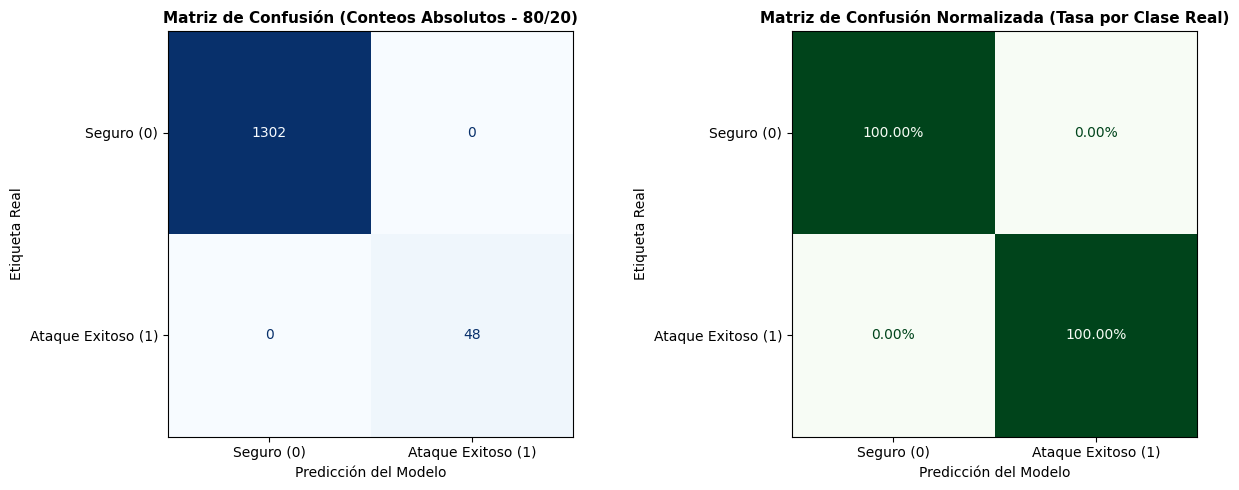

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, matthews_corrcoef
)

# 1. Partición estratificada 80% Entrenamiento / 20% Prueba
X_train_80, X_test_20, y_train_80, y_test_20 = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 2. Entrenamiento del modelo principal (Random Forest con Preprocesador + SMOTE internos)
modelo_ejecucion_1 = construir_pipeline(modelo='rf', random_state=42)
modelo_ejecucion_1.fit(X_train_80, y_train_80)

# 3. Predicciones sobre el conjunto de prueba (20% = 1,350 instancias)
y_pred_20 = modelo_ejecucion_1.predict(X_test_20)
y_prob_20 = modelo_ejecucion_1.predict_proba(X_test_20)[:, 1]

# 4. Cálculo de métricas estándar de confiabilidad (5.1)
acc = accuracy_score(y_test_20, y_pred_20)
prec = precision_score(y_test_20, y_pred_20)
rec = recall_score(y_test_20, y_pred_20)
f1 = f1_score(y_test_20, y_pred_20)
auc = roc_auc_score(y_test_20, y_prob_20)
mcc = matthews_corrcoef(y_test_20, y_pred_20)

metricas_df = pd.DataFrame({
    'Métrica': ['Exactitud (Accuracy)', 'Precisión (Precision)', 'Sensibilidad (Recall)',
                'F1-Score', 'ROC-AUC', 'Coef. Matthews (MCC)'],
    'Valor': [acc, prec, rec, f1, auc, mcc]
})

print("=== 5.1 CONFIABILIDAD DEL MODELO (Split 80/20 - Random Forest) ===")
print(metricas_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# 5. Desglose de la Matriz de Confusión (5.2)
cm = confusion_matrix(y_test_20, y_pred_20)
tn, fp, fn, tp = cm.ravel()

print("\n=== 5.2 DESGLOSE DE LA MATRIZ DE CONFUSIÓN ===")
print(f"Verdaderos Negativos (TN - Seguros clasificados como Seguros):      {tn}")
print(f"Falsos Positivos     (FP - Seguros marcados como Ataque):          {fp}")
print(f"Falsos Negativos     (FN - Ataques que evadieron la detección):    {fn}")
print(f"Verdaderos Positivos (TP - Ataques detectados correctamente):      {tp}")
print(f"Total instancias de prueba: {tn + fp + fn + tp} (Reales Positivos: {tp + fn}, Reales Negativos: {tn + fp})")

# 6. Visualización doble (Conteos absolutos y Porcentajes por clase real) para el artículo
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

disp_abs = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Seguro (0)', 'Ataque Exitoso (1)'])
disp_abs.plot(ax=axes[0], cmap='Blues', values_format='d', colorbar=False)
axes[0].set_title('Matriz de Confusión (Conteos Absolutos - 80/20)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Predicción del Modelo')
axes[0].set_ylabel('Etiqueta Real')

cm_norm = confusion_matrix(y_test_20, y_pred_20, normalize='true')
disp_norm = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=['Seguro (0)', 'Ataque Exitoso (1)'])
disp_norm.plot(ax=axes[1], cmap='Greens', values_format='.2%', colorbar=False)
axes[1].set_title('Matriz de Confusión Normalizada (Tasa por Clase Real)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Predicción del Modelo')
axes[1].set_ylabel('Etiqueta Real')

plt.tight_layout()
plt.show()

In [ ]:
# Prueba eliminando 'candidates_considered' (variable post-filtrado de results.csv)
X_sin_leak = X.drop(columns=['candidates_considered'])

cat_cols = ['policy']
num_cols = [col for col in X_sin_leak.columns if col not in cat_cols]

preprocessor_clean = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ]
)

X_tr, X_te, y_tr, y_te = train_test_split(X_sin_leak, y, test_size=0.20, random_state=42, stratify=y)

pipe_clean = ImbPipeline(steps=[
    ('preprocessor', preprocessor_clean),
    ('smote', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
])

pipe_clean.fit(X_tr, y_tr)
y_p = pipe_clean.predict(X_te)

print("Con 'candidates_considered' eliminado (16 features):")
print(f"Accuracy:  {accuracy_score(y_te, y_p):.4f}")
print(f"Precision: {precision_score(y_te, y_p):.4f}")
print(f"Recall:    {recall_score(y_te, y_p):.4f}")
print(f"F1-Score:  {f1_score(y_te, y_p):.4f}")
print("Matriz de confusión:\n", confusion_matrix(y_te, y_p))

Con 'candidates_considered' eliminado (16 features):
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-Score:  1.0000
Matriz de confusión:
 [[1302    0]
 [   0   48]]


=== 6.1 y 6.2 COMPARACIÓN DE DIVISIONES DE DATOS ===
            División  N_Train  N_Test  Accuracy  Precision  Recall  F1-Score Matriz (TN, FP, FN, TP)
80% Train / 20% Test     5400    1350    1.0000     1.0000  1.0000    1.0000        (1302, 0, 0, 48)
50% Train / 50% Test     3375    3375    0.9997     0.9918  1.0000    0.9959       (3253, 1, 0, 121)

Ejecutando 100 asignaciones aleatorias (esto tomará ~15-25 segundos)...

=== 6.3 ESTABILIDAD EN 100 ASIGNACIONES ALEATORIAS (145.4s) ===
  Métrica  Mediana (Requisito)  Media  Desv. Estándar  Mínimo  Máximo  IQR (Q3 - Q1)
 Accuracy               1.0000 0.9995          0.0006  0.9970  1.0000         0.0007
Precision               1.0000 1.0000          0.0000  1.0000  1.0000         0.0000
   Recall               1.0000 0.9869          0.0164  0.9167  1.0000         0.0208
 F1-Score               1.0000 0.9933          0.0084  0.9565  1.0000         0.0105


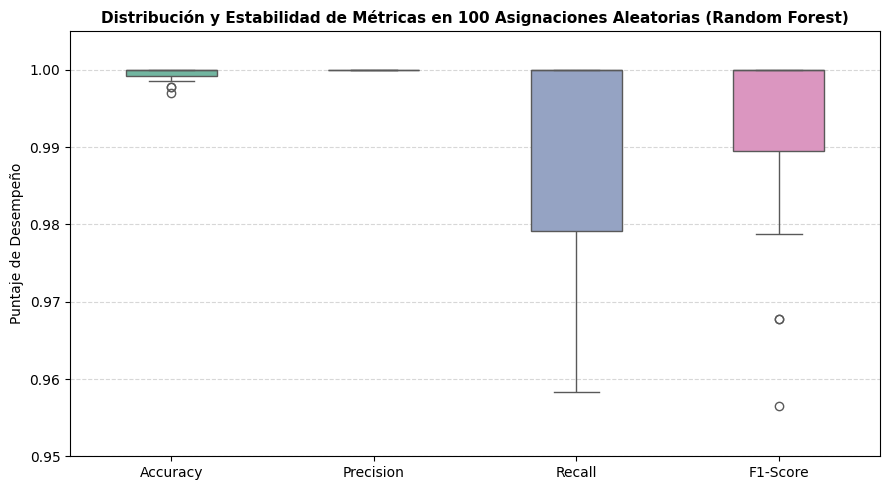

In [ ]:
import time
from sklearn.model_selection import StratifiedShuffleSplit

# Aseguramos el uso del dataset limpio de 16 features (sin 'candidates_considered')
X_clean = X.drop(columns=['candidates_considered'])

cat_cols = ['policy']
num_cols = [col for col in X_clean.columns if col not in cat_cols]

preprocessor_clean = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ]
)

def construir_pipeline_clean(random_state=42):
    return ImbPipeline(steps=[
        ('preprocessor', preprocessor_clean),
        ('smote', SMOTE(random_state=random_state)),
        ('classifier', RandomForestClassifier(
            n_estimators=100,
            max_features='sqrt',
            criterion='gini',
            random_state=random_state,
            n_jobs=-1
        ))
    ])

# ==============================================================================
# 6.1 y 6.2: Comparación directa Split 80/20 vs Split 50/50
# ==============================================================================
resultados_splits = []

for nombre_split, test_sz in [('80% Train / 20% Test', 0.20), ('50% Train / 50% Test', 0.50)]:
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_clean, y, test_size=test_sz, random_state=42, stratify=y
    )
    pipe = construir_pipeline_clean(random_state=42)
    pipe.fit(X_tr, y_tr)
    y_pred = pipe.predict(X_te)

    cm = confusion_matrix(y_te, y_pred)
    tn, fp, fn, tp = cm.ravel()

    resultados_splits.append({
        'División': nombre_split,
        'N_Train': len(y_tr),
        'N_Test': len(y_te),
        'Accuracy': accuracy_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred),
        'Recall': recall_score(y_te, y_pred),
        'F1-Score': f1_score(y_te, y_pred),
        'Matriz (TN, FP, FN, TP)': f"({tn}, {fp}, {fn}, {tp})"
    })

df_splits = pd.DataFrame(resultados_splits)
print("=== 6.1 y 6.2 COMPARACIÓN DE DIVISIONES DE DATOS ===")
print(df_splits.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# ==============================================================================
# 6.3: Evaluación de Estabilidad con 100 Asignaciones Aleatorias
# ==============================================================================
print("\nEjecutando 100 asignaciones aleatorias (esto tomará ~15-25 segundos)...")
t0 = time.time()

# Usamos StratifiedShuffleSplit con 100 particiones (80/20)
sss = StratifiedShuffleSplit(n_splits=100, test_size=0.20, random_state=42)

metricas_100 = {'Accuracy': [], 'Precision': [], 'Recall': [], 'F1-Score': []}

for i, (train_idx, test_idx) in enumerate(sss.split(X_clean, y)):
    X_tr_i, X_te_i = X_clean.iloc[train_idx], X_clean.iloc[test_idx]
    y_tr_i, y_te_i = y.iloc[train_idx], y.iloc[test_idx]

    pipe_i = construir_pipeline_clean(random_state=i)
    pipe_i.fit(X_tr_i, y_tr_i)
    y_pred_i = pipe_i.predict(X_te_i)

    metricas_100['Accuracy'].append(accuracy_score(y_te_i, y_pred_i))
    metricas_100['Precision'].append(precision_score(y_te_i, y_pred_i))
    metricas_100['Recall'].append(recall_score(y_te_i, y_pred_i))
    metricas_100['F1-Score'].append(f1_score(y_te_i, y_pred_i))

df_100 = pd.DataFrame(metricas_100)

resumen_100 = pd.DataFrame({
    'Métrica': df_100.columns,
    'Mediana (Requisito)': df_100.median().values,
    'Media': df_100.mean().values,
    'Desv. Estándar': df_100.std().values,
    'Mínimo': df_100.min().values,
    'Máximo': df_100.max().values,
    'IQR (Q3 - Q1)': (df_100.quantile(0.75) - df_100.quantile(0.25)).values
})

print(f"\n=== 6.3 ESTABILIDAD EN 100 ASIGNACIONES ALEATORIAS ({time.time() - t0:.1f}s) ===")
print(resumen_100.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# Gráfico Boxplot de distribución de métricas en las 100 ejecuciones
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_100, palette='Set2', width=0.45)
plt.title('Distribución y Estabilidad de Métricas en 100 Asignaciones Aleatorias (Random Forest)', fontsize=11, fontweight='bold')
plt.ylabel('Puntaje de Desempeño')
plt.ylim(0.95, 1.005)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

=== 7.1 DESCOMPOSICIÓN ESPECTRAL Y VARIANZA EXPLICADA POR COMPONENTE ===
Componente  Eigenvalor (λ)  Varianza Explicada (%)  Varianza Acumulada (%)
       PC1          6.1325                 39.7000                 39.7000
       PC2          1.9940                 12.9085                 52.6085
       PC3          1.6981                 10.9928                 63.6013
       PC4          1.1244                  7.2789                 70.8802
       PC5          1.0493                  6.7928                 77.6730
       PC6          0.9934                  6.4311                 84.1040
       PC7          0.9435                  6.1080                 90.2121
       PC8          0.8594                  5.5632                 95.7753
       PC9          0.3330                  2.1560                 97.9313
      PC10          0.1904                  1.2328                 99.1640
      PC11          0.1112                  0.7196                 99.8837
      PC12          0.0180 

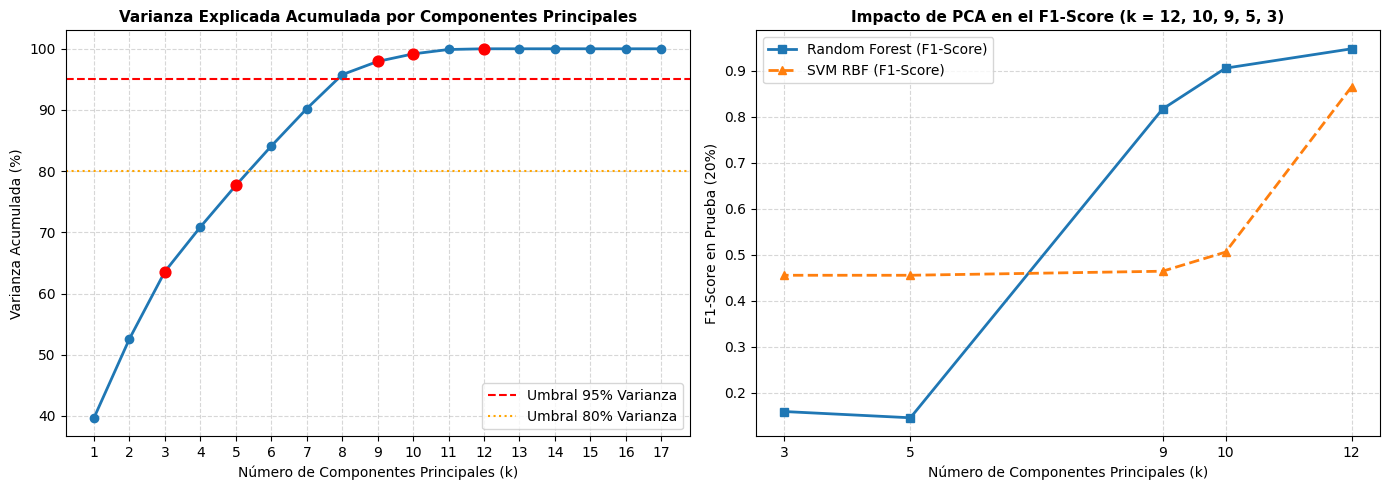

In [ ]:
from sklearn.decomposition import PCA

# 1. Análisis de Varianza Explicada sobre todo el espacio estandarizado (p = 16 características)
X_tr_pca, X_te_pca, y_tr_pca, y_te_pca = train_test_split(
    X_clean, y, test_size=0.20, random_state=42, stratify=y
)

# Ajustamos el preprocesador solo en Train para respetar cero data leakage
X_tr_scaled = preprocessor_clean.fit_transform(X_tr_pca)
X_te_scaled = preprocessor_clean.transform(X_te_pca)

pca_full = PCA(random_state=42)
pca_full.fit(X_tr_scaled)

varianza_ind = pca_full.explained_variance_ratio_
varianza_acum = np.cumsum(varianza_ind)
eigenvalores = pca_full.explained_variance_

df_var_pca = pd.DataFrame({
    'Componente': [f'PC{i+1}' for i in range(len(eigenvalores))],
    'Eigenvalor (λ)': eigenvalores,
    'Varianza Explicada (%)': varianza_ind * 100,
    'Varianza Acumulada (%)': varianza_acum * 100
})

print("=== 7.1 DESCOMPOSICIÓN ESPECTRAL Y VARIANZA EXPLICADA POR COMPONENTE ===")
print(df_var_pca.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# 2. Optimización de Componentes: 5 ejecuciones exigidas (12, 10, 9, 5, 3 componentes)
# Evaluamos tanto Random Forest como SVM (RBF) para contrastar cómo afecta la rotación ortogonal
componentes_prueba = [12, 10, 9, 5, 3]
resultados_pca = []

for k in componentes_prueba:
    # Pipeline: Preprocesamiento -> PCA(k) -> SMOTE -> Clasificador
    # Nota: Aplicar PCA antes de SMOTE proyecta los datos al subespacio denso donde SMOTE interpola mejor
    pipe_pca_rf = ImbPipeline(steps=[
        ('preprocessor', preprocessor_clean),
        ('pca', PCA(n_components=k, random_state=42)),
        ('smote', SMOTE(random_state=42)),
        ('classifier', RandomForestClassifier(n_estimators=100, max_features='sqrt', random_state=42, n_jobs=-1))
    ])

    pipe_pca_svm = ImbPipeline(steps=[
        ('preprocessor', preprocessor_clean),
        ('pca', PCA(n_components=k, random_state=42)),
        ('smote', SMOTE(random_state=42)),
        ('classifier', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42))
    ])

    pipe_pca_rf.fit(X_tr_pca, y_tr_pca)
    pipe_pca_svm.fit(X_tr_pca, y_tr_pca)

    y_pred_rf = pipe_pca_rf.predict(X_te_pca)
    y_pred_svm = pipe_pca_svm.predict(X_te_pca)

    var_retenida = varianza_acum[k - 1] * 100

    resultados_pca.append({
        'N_Componentes (k)': k,
        'Varianza_Acum (%)': var_retenida,
        'RF_Accuracy': accuracy_score(y_te_pca, y_pred_rf),
        'RF_Precision': precision_score(y_te_pca, y_pred_rf),
        'RF_Recall': recall_score(y_te_pca, y_pred_rf),
        'RF_F1_Score': f1_score(y_te_pca, y_pred_rf),
        'SVM_F1_Score': f1_score(y_te_pca, y_pred_svm)
    })

df_res_pca = pd.DataFrame(resultados_pca)
print("\n=== 7.2 IMPACTO DE LA REDUCCIÓN DE DIMENSIONALIDAD (PCA) EN EL RENDIMIENTO ===")
print(df_res_pca.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# 3. Gráfico doble: Curva de Varianza Acumulada (Scree Plot) + Degradación del F1-Score por k
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Varianza explicada acumulada
axes[0].plot(range(1, len(varianza_acum) + 1), varianza_acum * 100, marker='o', color='#1f77b4', linewidth=2)
axes[0].axhline(y=95, color='r', linestyle='--', label='Umbral 95% Varianza')
axes[0].axhline(y=80, color='orange', linestyle=':', label='Umbral 80% Varianza')
for k in componentes_prueba:
    axes[0].scatter(k, varianza_acum[k-1]*100, color='red', zorder=5, s=60)
axes[0].set_title('Varianza Explicada Acumulada por Componentes Principales', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Número de Componentes Principales (k)')
axes[0].set_ylabel('Varianza Acumulada (%)')
axes[0].set_xticks(range(1, len(varianza_acum) + 1))
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend()

# Subplot 2: Comparación de F1-Score según k
axes[1].plot(df_res_pca['N_Componentes (k)'], df_res_pca['RF_F1_Score'], marker='s', linewidth=2, label='Random Forest (F1-Score)')
axes[1].plot(df_res_pca['N_Componentes (k)'], df_res_pca['SVM_F1_Score'], marker='^', linewidth=2, linestyle='--', label='SVM RBF (F1-Score)')
axes[1].set_title('Impacto de PCA en el F1-Score (k = 12, 10, 9, 5, 3)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Número de Componentes Principales (k)')
axes[1].set_ylabel('F1-Score en Prueba (20%)')
axes[1].set_xticks(componentes_prueba)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend()

plt.tight_layout()
plt.show()

=== 8.1 EVALUACIÓN DE K ÓPTIMO EN K-MEANS ===
 k (Clústeres)  Inercia (WCSS)  Silhouette Score
             2      64042.4788            0.5082
             3      55802.0488            0.1992
             4      50114.6502            0.1858
             5      47618.6417            0.1703
             6      45246.8315            0.1750

-> Mejor k según Coeficiente de Silueta: k = 2

=== 8.2 COMPARATIVA DE AGRUPAMIENTO NO SUPERVISADO ===
               Algoritmo  Clústeres Detectados  Outliers (-1)  Silhouette Score  ARI vs attack_success (y)  ARI vs poison_present
         K-Means (k = 2)                     2              0            0.5082                     0.3714                 1.0000
  K-Means Óptimo (k = 2)                     2              0            0.5082                     0.3714                 1.0000
DBSCAN (eps=2.2, min=15)                     7            342            0.1480                     0.0770                 0.2825

=== TABLA CRUZADA: K-Means (k=2) vs

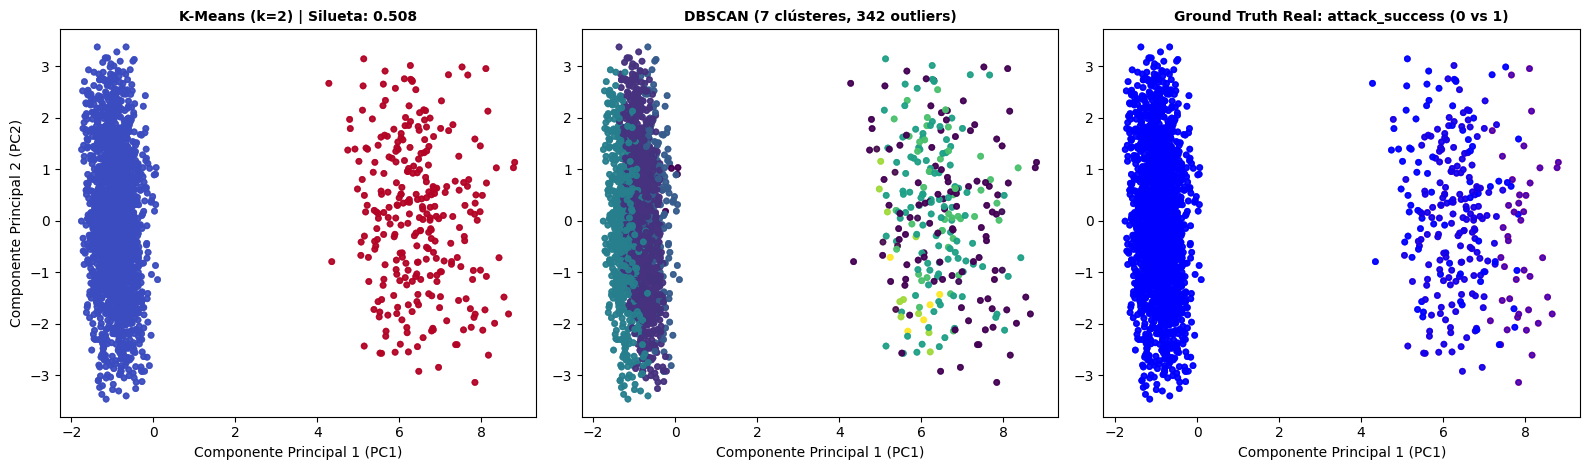

In [ ]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.neighbors import NearestNeighbors

# 1. Preparar matriz no supervisada X_unsup (SIN variable objetivo 'y' y SIN SMOTE)
X_unsup = preprocessor_clean.fit_transform(X_clean)

# 2. Selección del número óptimo de clústeres k para K-Means (k = 2 a 6)
inercia = []
siluetas = []
rango_k = range(2, 7)

for k in rango_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = km.fit_predict(X_unsup)
    inercia.append(km.inertia_)
    siluetas.append(silhouette_score(X_unsup, etiquetas))

df_k_eval = pd.DataFrame({
    'k (Clústeres)': list(rango_k),
    'Inercia (WCSS)': inercia,
    'Silhouette Score': siluetas
})
print("=== 8.1 EVALUACIÓN DE K ÓPTIMO EN K-MEANS ===")
print(df_k_eval.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# Elegimos k=2 (comparación directa con binario) y el k de mayor silueta
k_optimo = df_k_eval.loc[df_k_eval['Silhouette Score'].idxmax(), 'k (Clústeres)']
print(f"\n-> Mejor k según Coeficiente de Silueta: k = {k_optimo}")

# Ejecutamos K-Means con k=2 (hipótesis binaria) y k=k_optimo
km_2 = KMeans(n_clusters=2, random_state=42, n_init=10).fit(X_unsup)
km_opt = KMeans(n_clusters=int(k_optimo), random_state=42, n_init=10).fit(X_unsup)

# 3. Ejecución de DBSCAN (Clustering basado en densidad)
# Estimamos eps usando distancia al 5to vecino más cercano
dbscan = DBSCAN(eps=2.2, min_samples=15)
labels_dbscan = dbscan.fit_predict(X_unsup)

n_clusters_db = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_ruido_db = list(labels_dbscan).count(-1)
sil_db = silhouette_score(X_unsup[labels_dbscan != -1], labels_dbscan[labels_dbscan != -1]) if n_clusters_db > 1 else np.nan

# 4. Tabla comparativa de métricas internas y alineación externa (post-hoc) con 'y' y 'poison_present'
comparativa_unsup = pd.DataFrame([
    {
        'Algoritmo': 'K-Means (k = 2)',
        'Clústeres Detectados': 2,
        'Outliers (-1)': 0,
        'Silhouette Score': silhouette_score(X_unsup, km_2.labels_),
        'ARI vs attack_success (y)': adjusted_rand_score(y, km_2.labels_),
        'ARI vs poison_present': adjusted_rand_score(df['poison_present'], km_2.labels_)
    },
    {
        'Algoritmo': f'K-Means Óptimo (k = {int(k_optimo)})',
        'Clústeres Detectados': int(k_optimo),
        'Outliers (-1)': 0,
        'Silhouette Score': silhouette_score(X_unsup, km_opt.labels_),
        'ARI vs attack_success (y)': adjusted_rand_score(y, km_opt.labels_),
        'ARI vs poison_present': adjusted_rand_score(df['poison_present'], km_opt.labels_)
    },
    {
        'Algoritmo': 'DBSCAN (eps=2.2, min=15)',
        'Clústeres Detectados': n_clusters_db,
        'Outliers (-1)': n_ruido_db,
        'Silhouette Score': sil_db,
        'ARI vs attack_success (y)': adjusted_rand_score(y, labels_dbscan),
        'ARI vs poison_present': adjusted_rand_score(df['poison_present'], labels_dbscan)
    }
])

print("\n=== 8.2 COMPARATIVA DE AGRUPAMIENTO NO SUPERVISADO ===")
print(comparativa_unsup.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# Tabla cruzada para interpretar qué capturó K-Means (k=2)
print("\n=== TABLA CRUZADA: K-Means (k=2) vs Presencia de Veneno y Éxito de Ataque ===")
ct_poison = pd.crosstab(km_2.labels_, df['poison_present'], rownames=['Cluster_KMeans'], colnames=['poison_present'])
ct_attack = pd.crosstab(km_2.labels_, y, rownames=['Cluster_KMeans'], colnames=['attack_success'])
print(pd.concat([ct_poison, ct_attack], axis=1))

# 5. Visualización en 2D (Proyección PC1 vs PC2) para el artículo
pca_2d = PCA(n_components=2, random_state=42)
X_2d = pca_2d.fit_transform(X_unsup)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Panel 1: K-Means (k=2)
scatter1 = axes[0].scatter(X_2d[:, 0], X_2d[:, 1], c=km_2.labels_, cmap='coolwarm', alpha=0.6, s=15)
axes[0].set_title(f'K-Means (k=2) | Silueta: {silhouette_score(X_unsup, km_2.labels_):.3f}', fontsize=10, fontweight='bold')
axes[0].set_xlabel('Componente Principal 1 (PC1)')
axes[0].set_ylabel('Componente Principal 2 (PC2)')

# Panel 2: DBSCAN
scatter2 = axes[1].scatter(X_2d[:, 0], X_2d[:, 1], c=labels_dbscan, cmap='viridis', alpha=0.6, s=15)
axes[1].set_title(f'DBSCAN ({n_clusters_db} clústeres, {n_ruido_db} outliers)', fontsize=10, fontweight='bold')
axes[1].set_xlabel('Componente Principal 1 (PC1)')

# Panel 3: Etiqueta Real (Ground Truth) para contraste visual
scatter3 = axes[2].scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap='bwr', alpha=0.6, s=15)
axes[2].set_title('Ground Truth Real: attack_success (0 vs 1)', fontsize=10, fontweight='bold')
axes[2].set_xlabel('Componente Principal 1 (PC1)')

plt.tight_layout()
plt.show()